# Requisitos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Carregamento dos dados

In [2]:
df_train = pd.read_csv("../../dados/treino.csv")
df_val = pd.read_csv("../../dados/validacao.csv")

# Feature Engineering

In [3]:
df_train["date"] = pd.to_datetime(df_train["date"])
df_val["date"] = pd.to_datetime(df_val["date"])

In [4]:
df_train["year"] = df_train["date"].dt.year
df_train["trimester"] = (df_train["date"].dt.month - 1) // 3
df_train["month"] = df_train["date"].dt.month
df_train["week"] = (df_train["date"].dt.day - 1) // 7
df_train["weekday"] = df_train["date"].dt.weekday
df_train["week_of_year"] = df_train["date"].dt.strftime("%U")

df_val["year"] = df_val["date"].dt.year
df_val["trimester"] = (df_val["date"].dt.month - 1) // 3
df_val["month"] = df_val["date"].dt.month
df_val["week"] = (df_val["date"].dt.day - 1) // 7
df_val["weekday"] = df_val["date"].dt.weekday
df_val["week_of_year"] = df_val["date"].dt.strftime("%U")

In [5]:
df_train

,date,store_total,FOODS,HOBBIES,year,trimester,month,week,weekday,week_of_year
0,2011-01-29,4337,3239,556,2011,0,1,4,5,04
1,2011-01-30,4155,3137,498,2011,0,1,4,6,05
2,2011-01-31,2816,2008,415,2011,0,1,4,0,05
3,2011-02-01,3051,2258,392,2011,0,2,0,1,05
4,2011-02-02,2630,2032,268,2011,0,2,0,2,05
...,...,...,...,...,...,...,...,...,...,...
1880,2016-03-23,3770,2554,454,2016,0,3,3,2,12
1881,2016-03-24,3970,2681,474,2016,0,3,3,3,12
1882,2016-03-25,4904,3421,446,2016,0,3,3,4,12
1883,2016-03-26,6139,4251,610,2016,0,3,3,5,12


# Visualização das séries

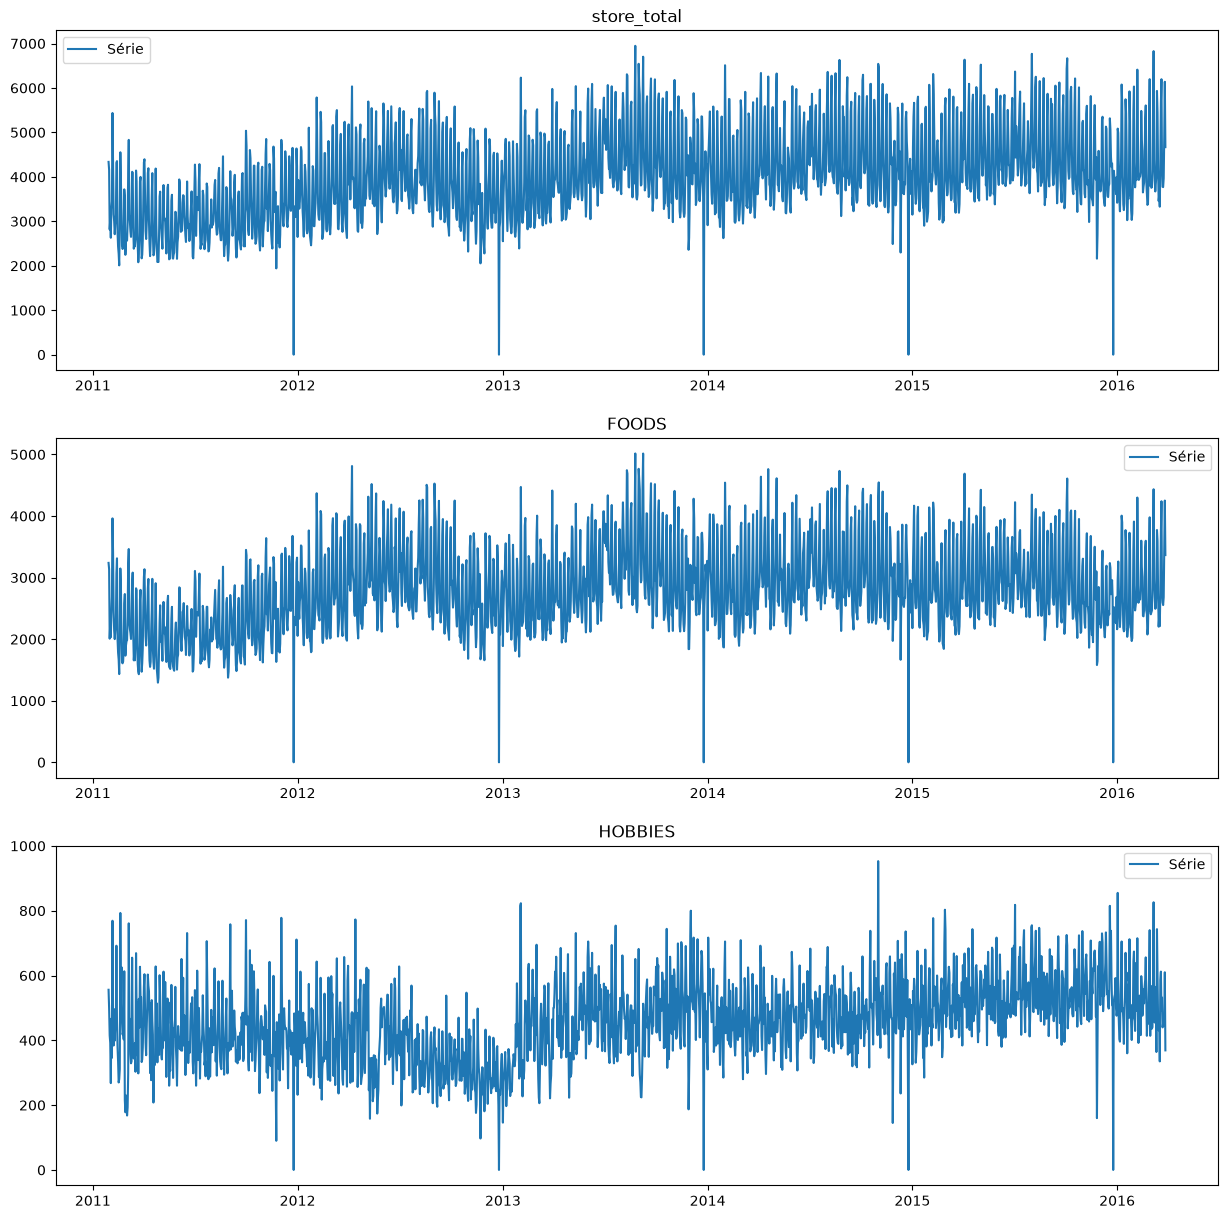

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(15, 15))
axes = np.ravel(axes)
axes[0].plot(df_train["date"], df_train["store_total"], label="Série")
axes[0].set(title="store_total")
axes[0].legend()

axes[1].plot(df_train["date"], df_train["FOODS"], label="Série")
axes[1].set(title="FOODS")
axes[1].legend()

axes[2].plot(df_train["date"], df_train["HOBBIES"], label="Série")
axes[2].set(title="HOBBIES")
axes[2].legend()


# Diagnóstico Visual de Tendência (Média Móvel)

In [7]:
window = 3*30

# Media movel do conjunto de treino
df_train["store_total_mean_movel"] = df_train['store_total'].rolling(window=window).mean().bfill()
df_train["FOODS_mean_movel"] = df_train['FOODS'].rolling(window=window).mean().bfill()
df_train["HOBBIES_mean_movel"] = df_train['HOBBIES'].rolling(window=window).mean().bfill()

# Media movel do conjunto de validacao
df_val["store_total_mean_movel"] = df_val['store_total'].rolling(window=window).mean().bfill()
df_val["FOODS_mean_movel"] = df_val['FOODS'].rolling(window=window).mean().bfill()
df_val["HOBBIES_mean_movel"] = df_val['HOBBIES'].rolling(window=window).mean().bfill()

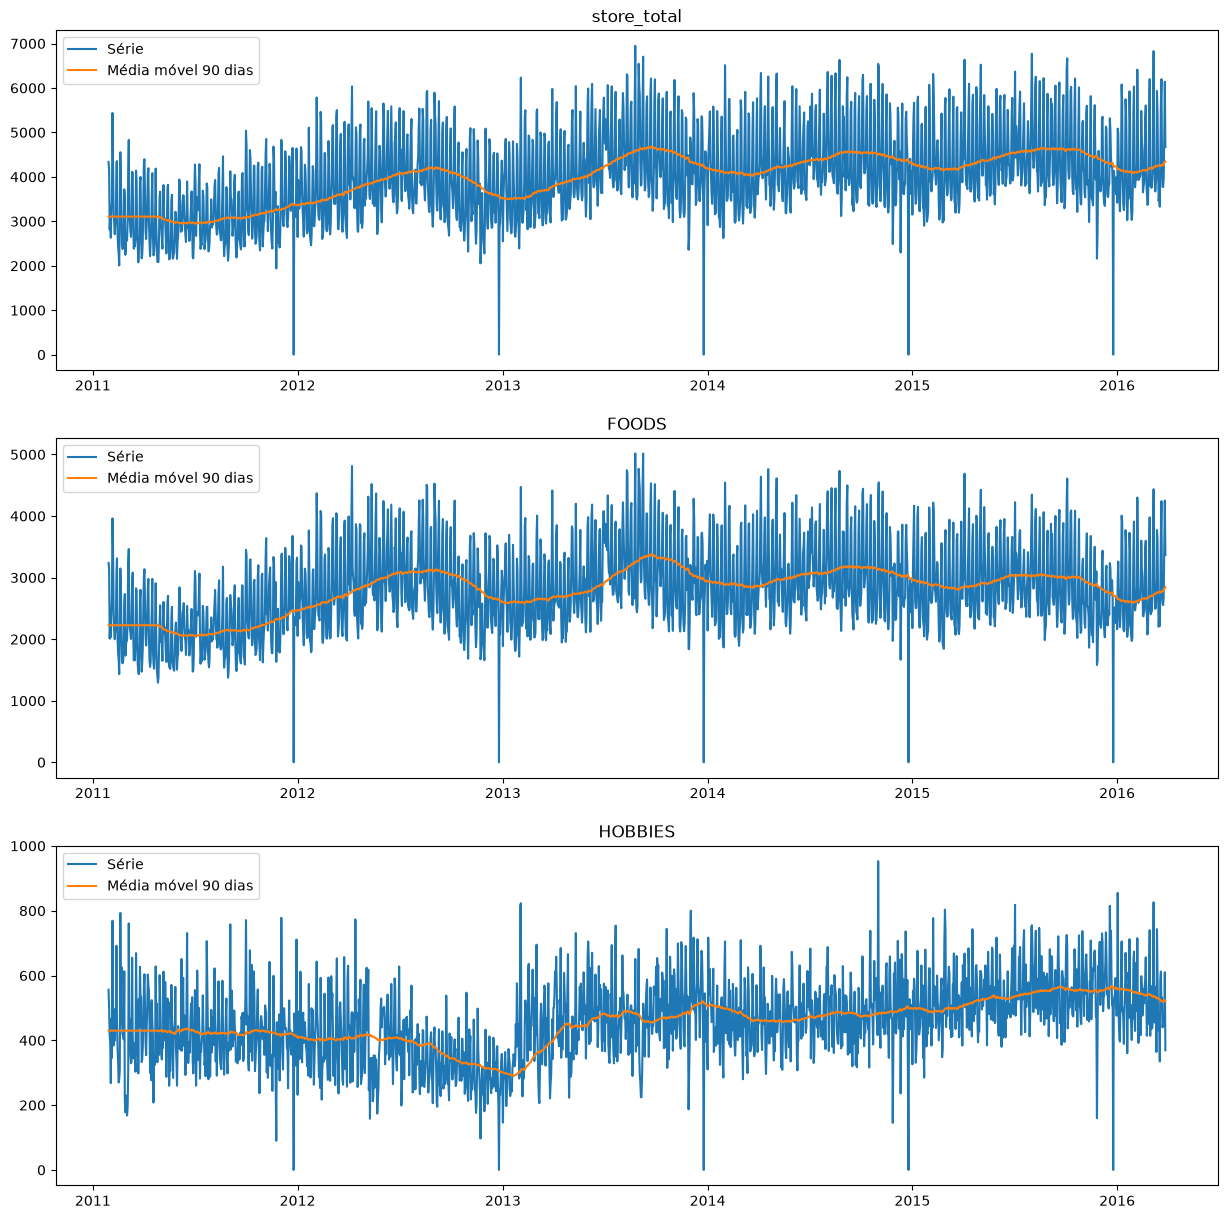

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(15, 15))
axes = np.ravel(axes)
axes[0].plot(df_train["date"], df_train["store_total"], label="Série")
axes[0].plot(df_train["date"], df_train["store_total_mean_movel"], label=f"Média móvel {window} dias")
axes[0].set(title="store_total")
axes[0].legend()

axes[1].plot(df_train["date"], df_train["FOODS"], label="Série")
axes[1].plot(df_train["date"], df_train["FOODS_mean_movel"], label=f"Média móvel {window} dias")
axes[1].set(title="FOODS")
axes[1].legend()

axes[2].plot(df_train["date"], df_train["HOBBIES"], label="Série")
axes[2].plot(df_train["date"], df_train["HOBBIES_mean_movel"], label=f"Média móvel {window} dias")
axes[2].set(title="HOBBIES")
axes[2].legend()

# Análise de Sazonalidades

### Overlay por período

In [9]:
def get_sazonalidade_overlay(
    df: pd.DataFrame, 
    group_col: str | list[str], 
    x_col: str | list[str], 
    y_col: str | list[str]
) -> pd.DataFrame:
    df_sazon = (
        df
        .pivot_table(values=y_col, index=x_col, columns=group_col, aggfunc='sum')
        # .reset_index()
    )
    
    return df_sazon

In [10]:
def plot_sazonalidade_overlay(
    df_sazon: pd.DataFrame,
    series: str | list[str], 
    legend_title: str
):
    s_qtt = len(series)
    fig, axes = plt.subplots(s_qtt, 1, figsize=(15, 5*s_qtt))
    axes = np.ravel([axes])
    
    # Faz o plot em cada uma das series
    for i, each_serie in enumerate(series):
        df_sazon[each_serie].plot(ax=axes[i], marker='.')
        axes[i].set(title=each_serie)
        axes[i].legend(title=legend_title, bbox_to_anchor=(1.1, 1), loc="upper right")

In [11]:
train_sazon_trimester = get_sazonalidade_overlay(df=df_train, group_col="year", x_col="trimester", y_col=["store_total", "FOODS", "HOBBIES"])
train_sazon_month     = get_sazonalidade_overlay(df=df_train, group_col="year", x_col="month", y_col=["store_total", "FOODS", "HOBBIES"])
train_sazon_week      = get_sazonalidade_overlay(df=df_train, group_col="month", x_col="week", y_col=["store_total", "FOODS", "HOBBIES"])
train_sazon_weekday   = get_sazonalidade_overlay(df=df_train, group_col="week", x_col="weekday", y_col=["store_total", "FOODS", "HOBBIES"])

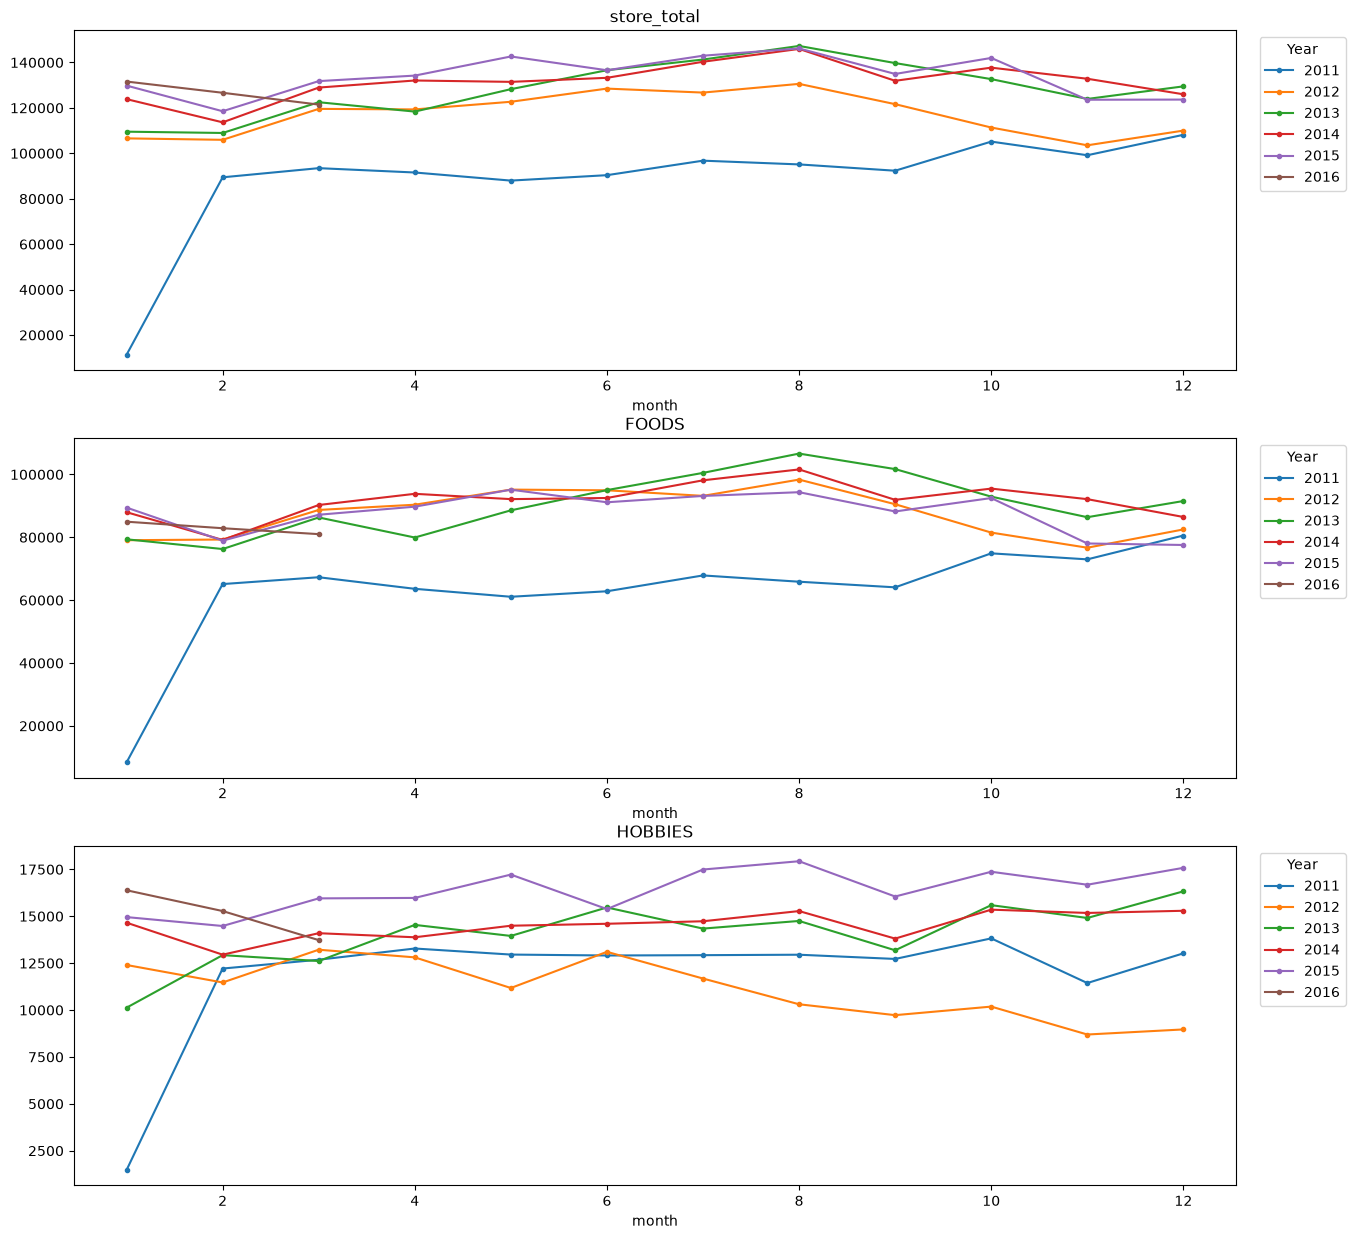

In [12]:
plot_sazonalidade_overlay(df_sazon=train_sazon_month, series=["store_total", "FOODS", "HOBBIES"], legend_title="Year")

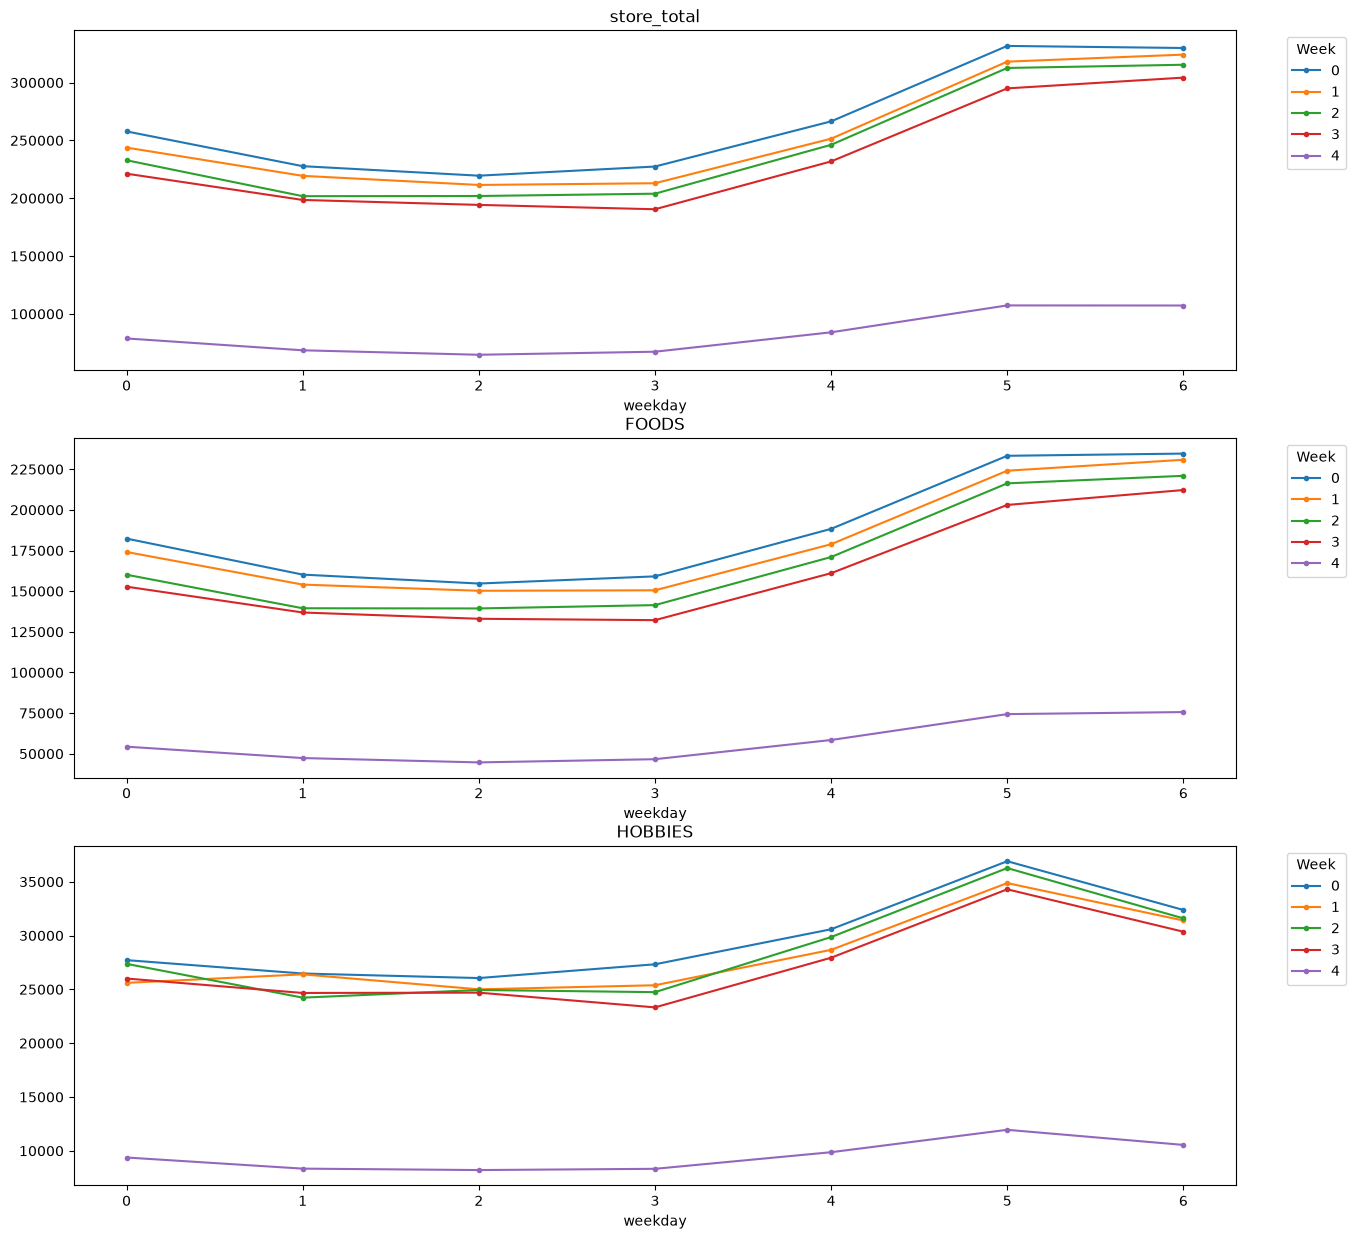

In [13]:
plot_sazonalidade_overlay(df_sazon=train_sazon_weekday, series=["store_total", "FOODS", "HOBBIES"], legend_title="Week")

### Série sem Tendência:

In [14]:
series = ["store_total", "FOODS", "HOBBIES"]

# Cria as colunas de series sem tendencia
for each_serie in series:
    df_train[f"{each_serie}_without_trend"] = df_train[each_serie] - df_train[f"{each_serie}_mean_movel"]

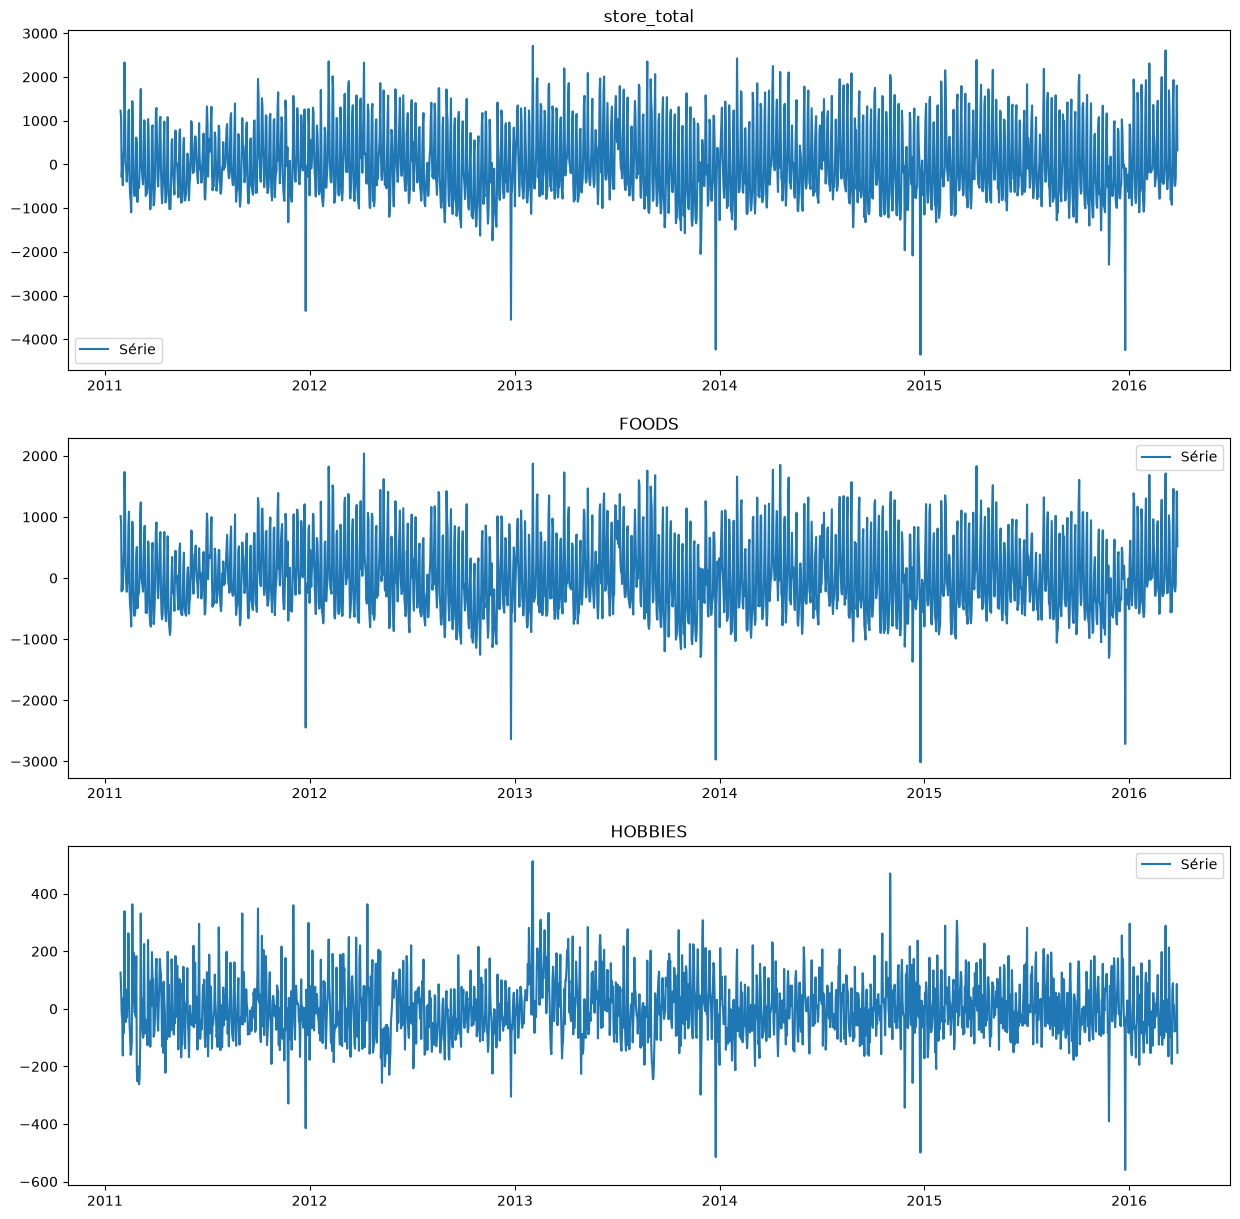

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(15, 15))
axes = np.ravel(axes)
axes[0].plot(df_train["date"], df_train["store_total_without_trend"], label="Série")
axes[0].set(title="store_total")
axes[0].legend()

axes[1].plot(df_train["date"], df_train["FOODS_without_trend"], label="Série")
axes[1].set(title="FOODS")
axes[1].legend()

axes[2].plot(df_train["date"], df_train["HOBBIES_without_trend"], label="Série")
axes[2].set(title="HOBBIES")
axes[2].legend()


### Boxplot por fase do período

In [16]:
def plot_sazonalidade_boxplot(
    df: pd.DataFrame, 
    group_col: str | list[str], 
    y_col: str | list[str]
) -> pd.DataFrame:
    y_col = np.ravel([y_col])
    fig, axes = plt.subplots(y_col.size, 1, figsize=(15, 5*y_col.size))
    axes = np.ravel([axes])
    for ax, each_y in zip(axes, y_col):
        df.boxplot(column=each_y, by=group_col, ax=ax)
        ax.grid(False)

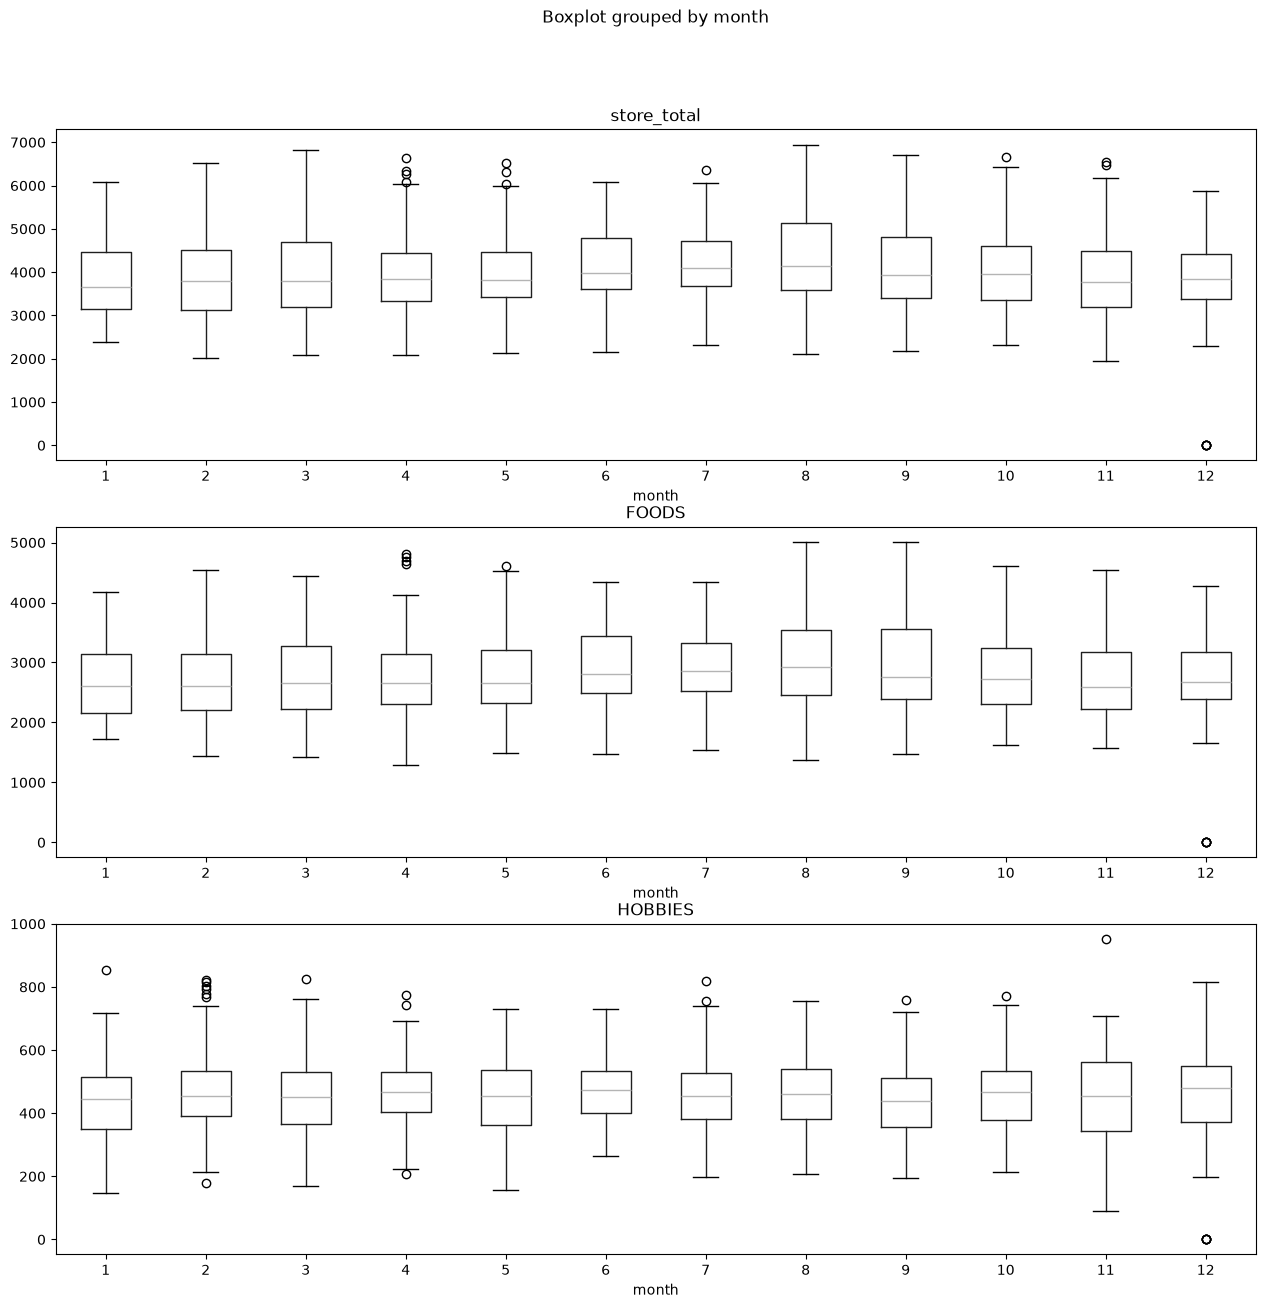

In [17]:
plot_sazonalidade_boxplot(df=df_train, group_col="month", y_col=series)

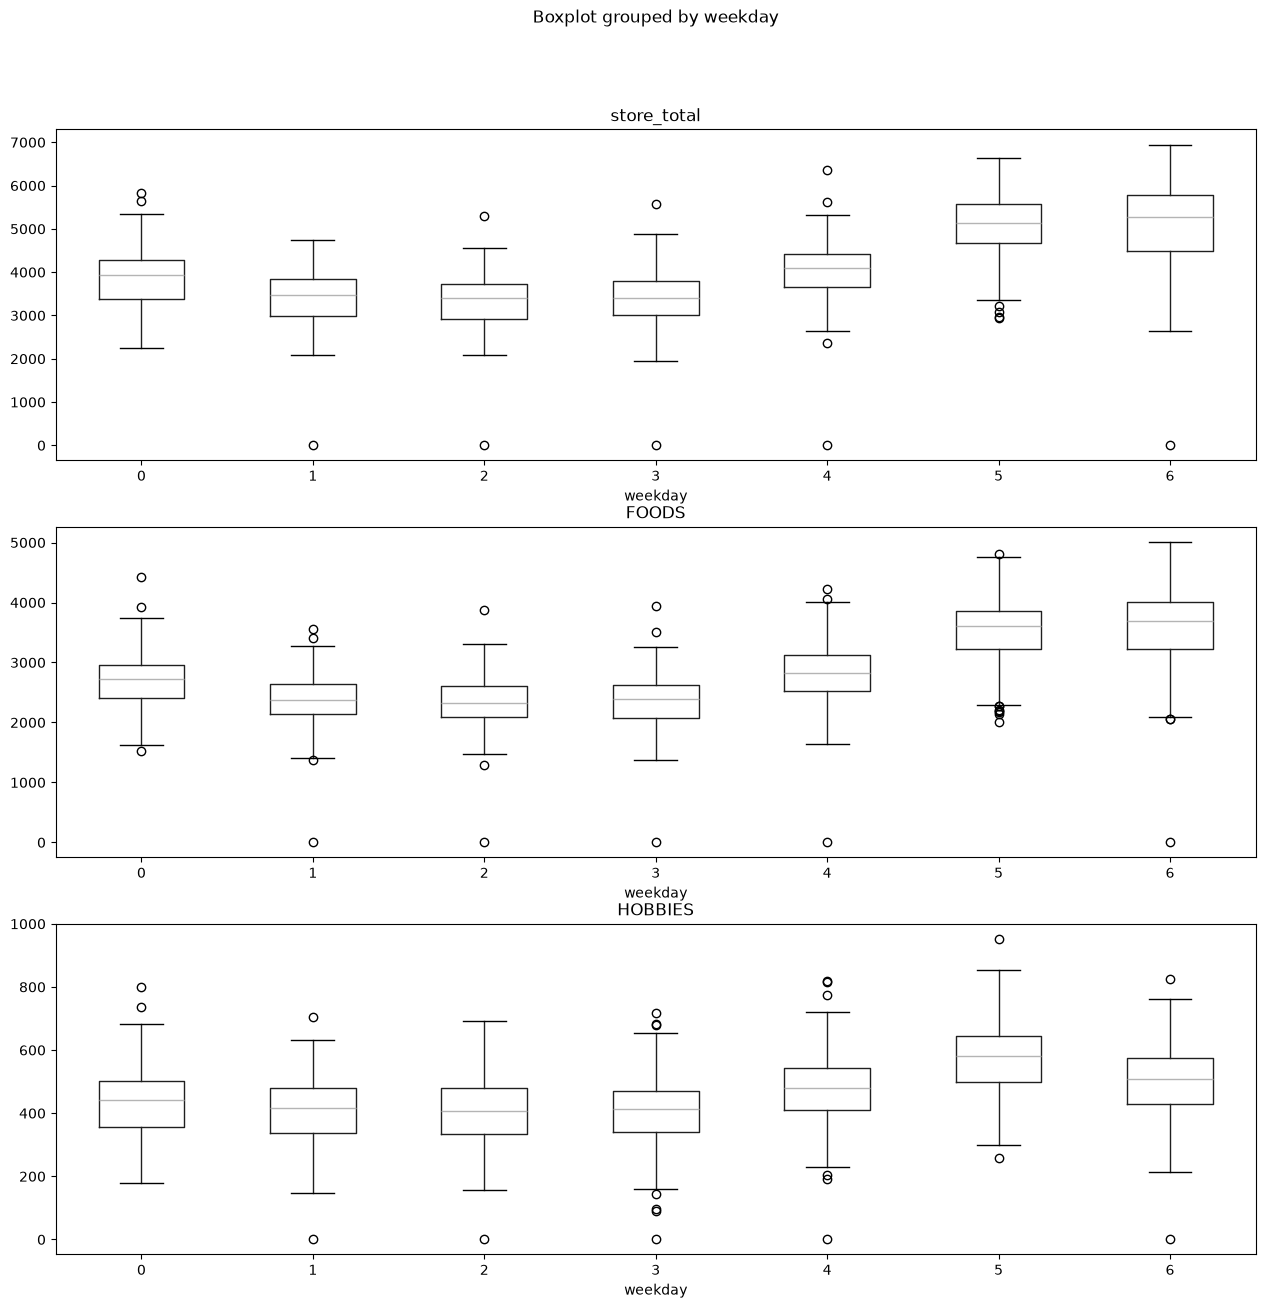

In [18]:
plot_sazonalidade_boxplot(df=df_train, group_col="weekday", y_col=series)

### Estimativa para a Sazonalidade (Média Semanal das Séries sem Tendência)

In [19]:
estimativa_sazonalidade = (
    df_train
    .groupby("week_of_year")[[f"{s}_without_trend" for s in series]].mean()
    .rename(columns={f"{col}_without_trend": f"{col}_week_mean" for col in series})
    .reset_index()
)

[Text(0.5, 1.0, 'HOBBIES_Week_Year'), Text(0.5, 0, 'Week of Year')]

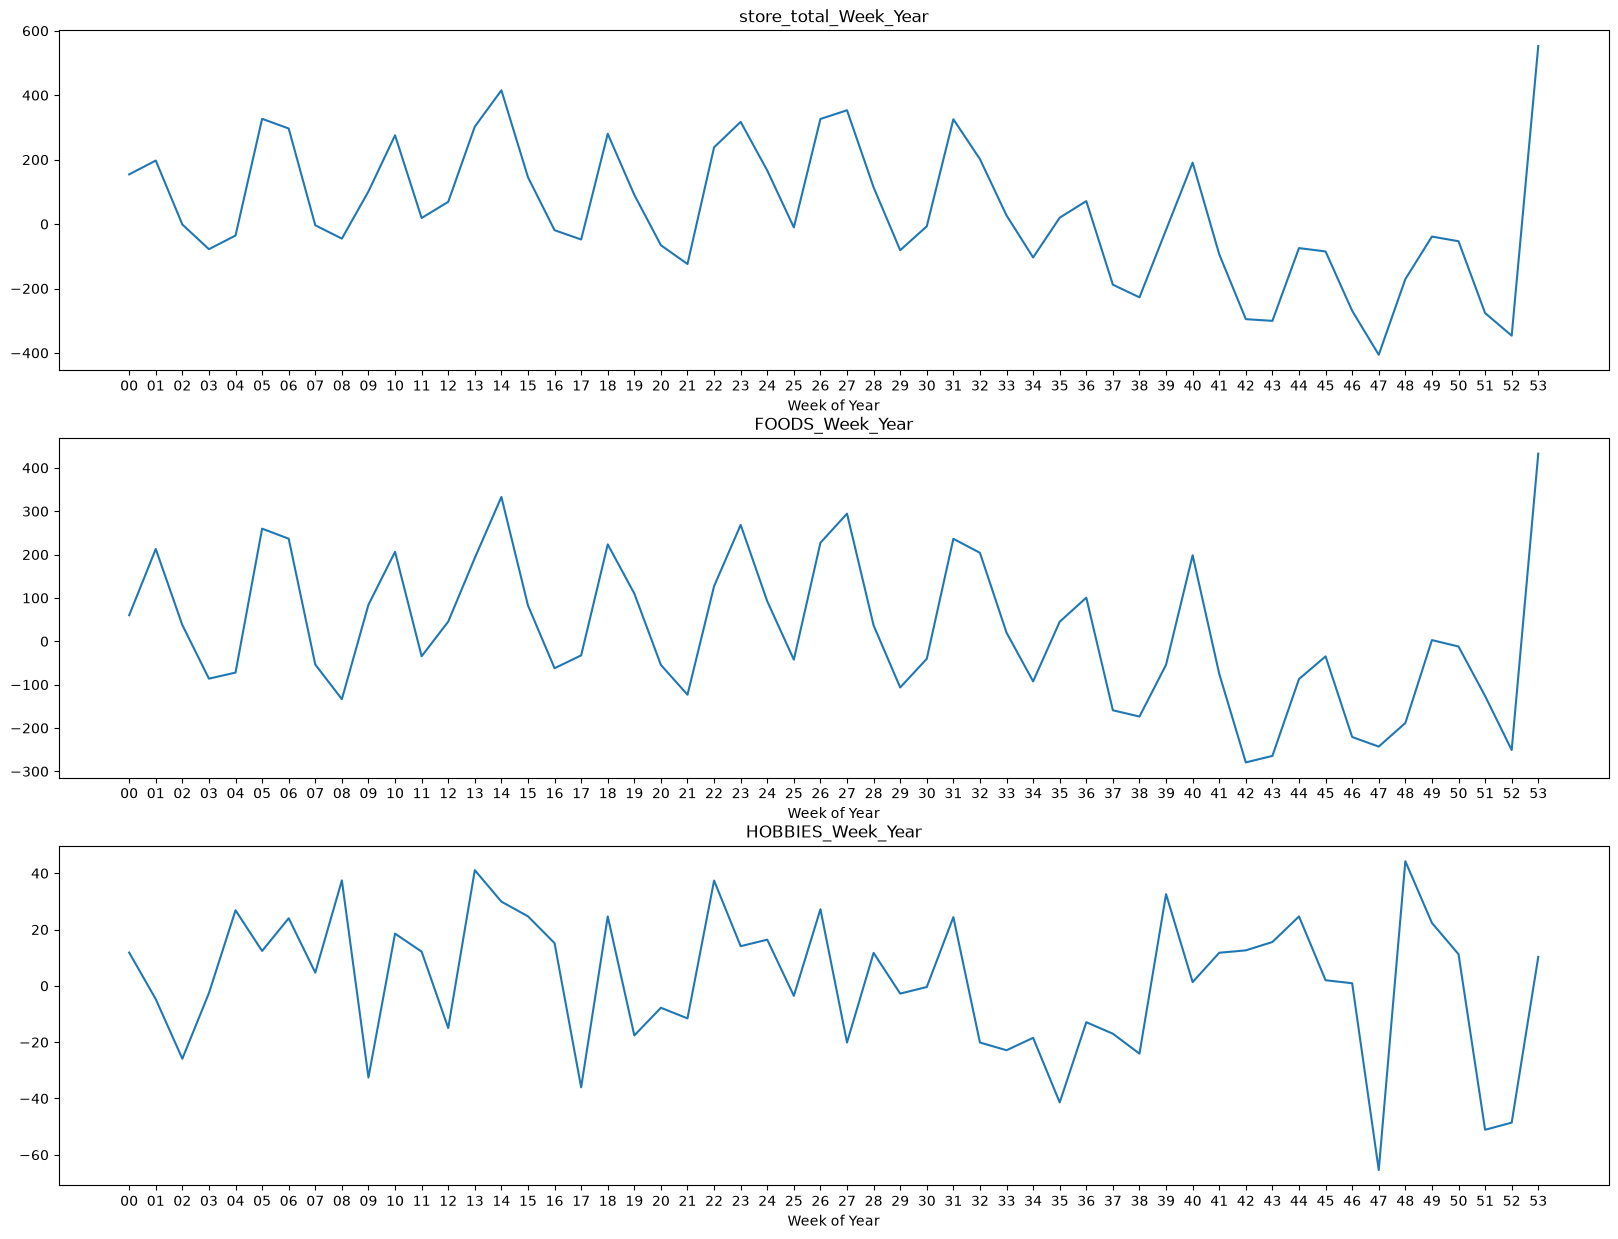

In [20]:
fig, axes = plt.subplots(3, 1, figsize=(20, 15))
axes = np.ravel(axes)
axes[0].plot(estimativa_sazonalidade["week_of_year"], estimativa_sazonalidade["store_total_week_mean"])
axes[0].set(title="store_total_Week_Year", xlabel="Week of Year")

axes[1].plot(estimativa_sazonalidade["week_of_year"], estimativa_sazonalidade["FOODS_week_mean"])
axes[1].set(title="FOODS_Week_Year", xlabel="Week of Year")

axes[2].plot(estimativa_sazonalidade["week_of_year"], estimativa_sazonalidade["HOBBIES_week_mean"])
axes[2].set(title="HOBBIES_Week_Year", xlabel="Week of Year")


In [21]:
df_train = df_train.merge(estimativa_sazonalidade, on="week_of_year", how="left").sort_values("date")
for each_serie in series:
    df_train[f"{each_serie}_residuo"] = df_train[f"{each_serie}_without_trend"] - df_train[f"{each_serie}_week_mean"]

[Text(0.5, 1.0, 'HOBBIES_Residuo'), Text(0.5, 0, 'date')]

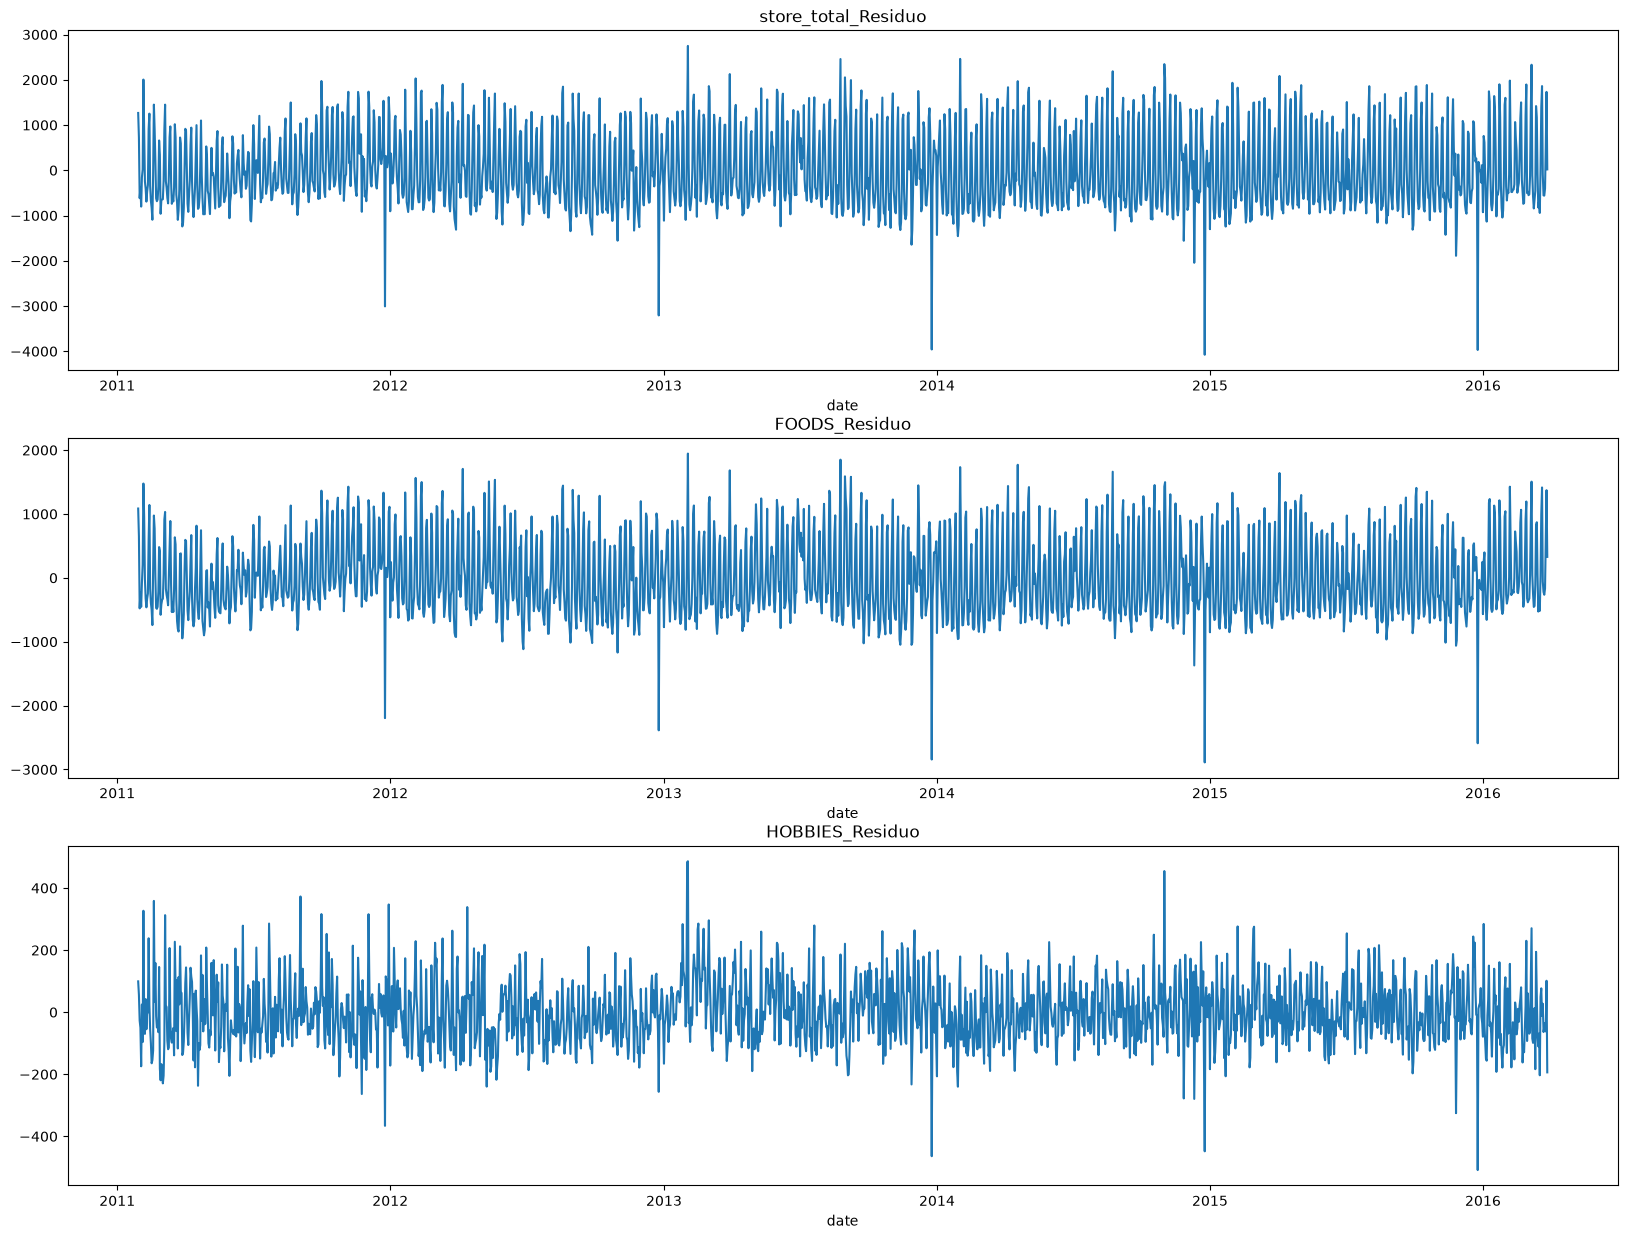

In [22]:
fig, axes = plt.subplots(3, 1, figsize=(20, 15))
axes = np.ravel(axes)
axes[0].plot(df_train["date"], df_train["store_total_residuo"])
axes[0].set(title="store_total_Residuo", xlabel="date")

axes[1].plot(df_train["date"], df_train["FOODS_residuo"])
axes[1].set(title="FOODS_Residuo", xlabel="date")

axes[2].plot(df_train["date"], df_train["HOBBIES_residuo"])
axes[2].set(title="HOBBIES_Residuo", xlabel="date")

### Funções Estatísticas

In [110]:
def acvf_amostral(serie: pd.Series, h: int):
    T              = serie.size
    serie          = np.asarray(serie).astype(float)
    desvios        = (serie - serie.mean())
    desvios_Y_t_h  = desvios[h:]
    desvios_Y_t    = desvios[:T-h]
    # Calcula a ACVF amostral de h
    return np.dot(desvios_Y_t_h, desvios_Y_t) / T


def acf(serie: pd.Series, h: int):
    if h == 0: return 1.0
    # Calcula a ACVF amostral de h e de 0
    cov_h = acvf_amostral(serie=serie, h=h)
    cov_0 = acvf_amostral(serie=serie, h=0)
    
    return float(cov_h / cov_0)

In [39]:
def levinson_durbin_pacf(serie: pd.Series, max_lag: int):
    # Calcula a ACF global para todos os lags de 0 ate max_lag
    mean = serie.mean()
    var = serie.var(ddof=0)
    
    if var == 0:
        return np.zeros(max_lag + 1)
        
    y = serie.values - mean
    
    # Vetor de autocorrelacoes rho de 0 ate max_lag
    rho = np.zeros(max_lag + 1)
    rho[0] = 1.0
    for h in range(1, max_lag + 1):
        cov_h = np.mean(y[:-h] * y[h:])
        rho[h] = cov_h / var

    # Inicializacao do Levinson-Durbin (Lag 1)
    pacf = np.zeros(max_lag + 1)
    pacf[0] = 1.0
    
    if max_lag == 0:
        return pacf

    # Para lag 1
    phi_prev = np.array([rho[1]])
    pacf[1] = rho[1]
    v = 1.0 - rho[1]**2

    # Loop de recursao para k = 2 ate max_lag
    for k in range(2, max_lag + 1):
        # Calcula phi_{k,k} (PACF no lag k)
        numerador = rho[k] - np.dot(phi_prev, rho[1:k][::-1])
        phi_kk = numerador / v
        
        pacf[k] = phi_kk
        
        # Atualiza os coeficientes anteriores (phi_{k, j})
        phi_curr = np.zeros(k)
        phi_curr[:-1] = phi_prev - phi_kk * phi_prev[::-1]
        phi_curr[-1] = phi_kk
        
        # Atualiza a variancia do erro v_k
        v = v * (1.0 - phi_kk**2)
        
        # Prepara para a proxima iteração
        phi_prev = phi_curr

    return pacf

In [ ]:
def compute_serie_autocorrel(df: pd.DataFrame, serie: str, max_lag: int):
    lags = np.arange(max_lag+1)
    acfs = np.array([
        acf(serie=df[serie], h=h) 
        for h in lags
    ])
    pacfs = levinson_durbin_pacf(serie=df[serie], max_lag=max_lag)
    return lags, acfs, pacfs

In [113]:
df_train.columns

Index(['date', 'store_total', 'FOODS', 'HOBBIES', 'year', 'trimester', 'month',
       'week', 'weekday', 'week_of_year', 'store_total_mean_movel',
       'FOODS_mean_movel', 'HOBBIES_mean_movel', 'store_total_without_trend',
       'FOODS_without_trend', 'HOBBIES_without_trend', 'store_total_week_mean',
       'FOODS_week_mean', 'HOBBIES_week_mean', 'store_total_residuo',
       'FOODS_residuo', 'HOBBIES_residuo'],
      dtype='str')

In [120]:
def plot_acf_pacf(lags, acfs, banda_acf: np.array, pacfs, banda_pacf: np.array, serie_name: str, axes=None):
    if axes is None:
        fig, axes = plt.subplots(2, 1, figsize=(10, 8))
        
    axes[0].hlines(0, xmin=lags.min(), xmax=lags.max(), ls='-', color="gray")
    axes[0].axhspan(-banda_acf.max(), banda_acf.max(), color='gray', alpha=0.3, label='$\\pm 1.96 / \\sqrt{T}$')
    axes[0].plot(lags, banda_acf, alpha=0.3, color="gray")
    axes[0].plot(lags, -banda_acf, alpha=0.3, color="gray")
    axes[0].vlines(x=lags, ymin=np.zeros_like(lags), ymax=acfs)
    axes[0].scatter(lags, acfs, marker=".")
    axes[0].set(
        xlim=(-0.2, lags.max()+0.2),
        ylim=(-1.1, 1.1),
        title=f"{serie_name} ACF"
    )
    axes[0].legend()

    axes[1].hlines(0, xmin=lags.min(), xmax=lags.max(), ls='-', color="gray")
    axes[1].axhspan(-banda_pacf.max(), banda_pacf.max(), color='gray', alpha=0.3, label='$\\pm 1.96 / \\sqrt{T}$')
    axes[1].plot(lags, banda_pacf, alpha=0.3, color="gray")
    axes[1].plot(lags, -banda_pacf, alpha=0.3, color="gray")
    axes[1].vlines(x=lags, ymin=np.zeros_like(lags), ymax=pacfs)
    axes[1].scatter(lags, pacfs, marker=".")
    axes[1].set(
        xlim=(-0.2, lags.max()+0.2),
        ylim=(-1.1, 1.1),
        title=f"{serie_name} PACF"
    )
    axes[1].legend()

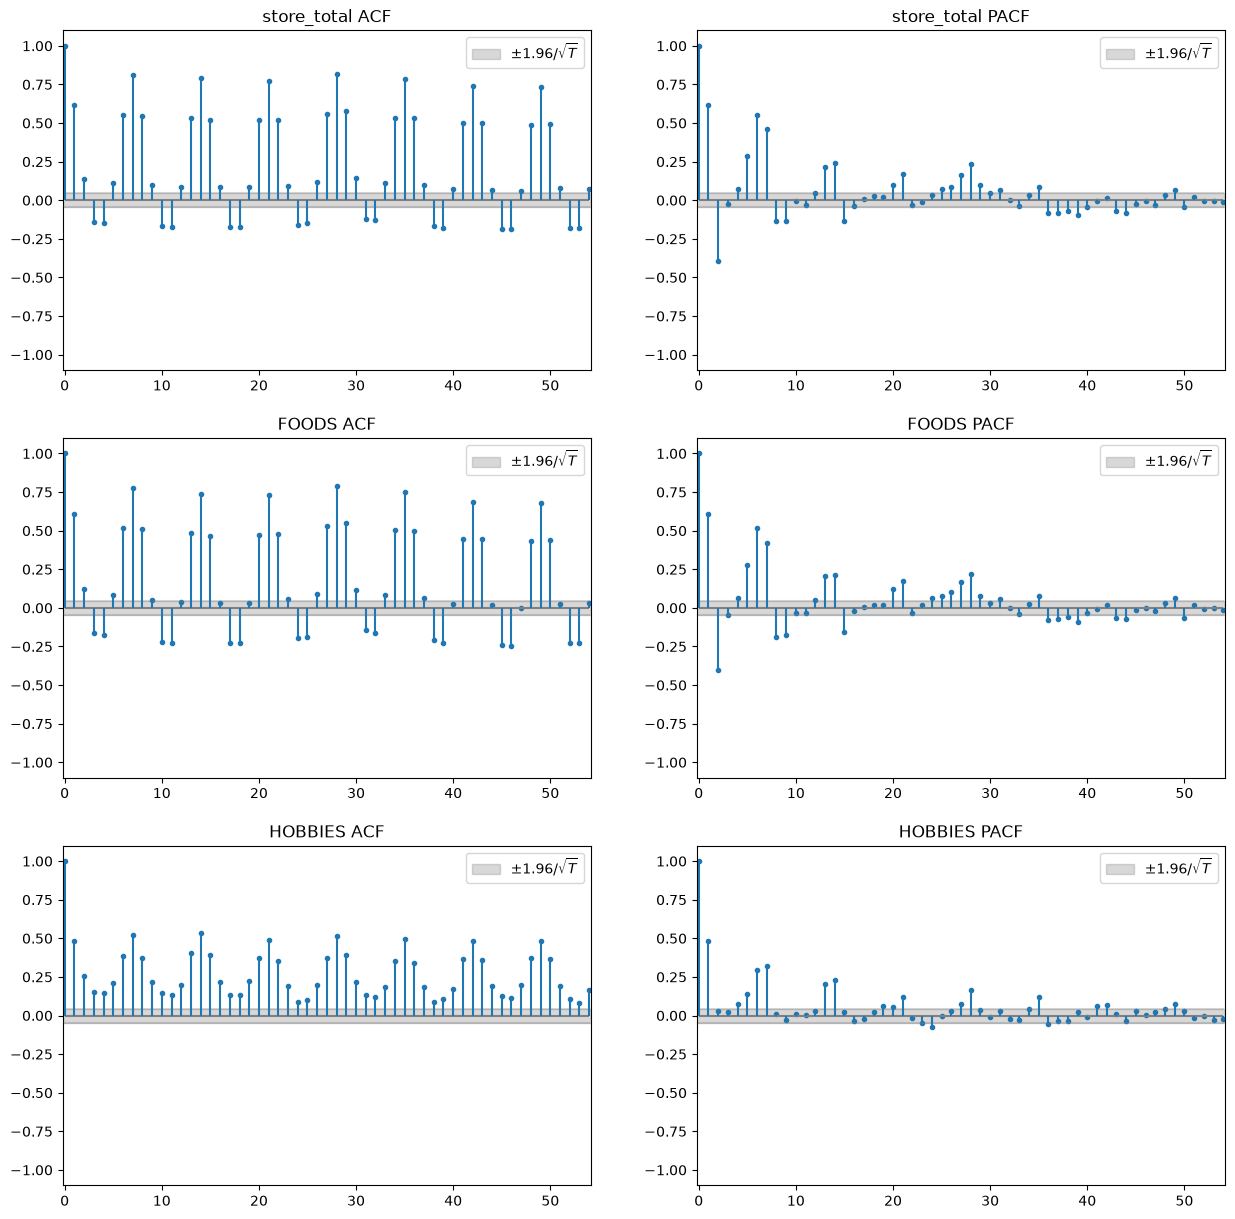

In [122]:
max_lag = 54
lags, acfs_store_total, pacfs_store_total = compute_serie_autocorrel(df=df_train, serie="store_total", max_lag=max_lag)
lags, acfs_FOODS, pacfs_FOODS = compute_serie_autocorrel(df=df_train, serie="FOODS", max_lag=max_lag)
lags, acfs_HOBBIES, pacfs_HOBBIES = compute_serie_autocorrel(df=df_train, serie="HOBBIES", max_lag=max_lag)
banda_pacf = banda_acf = np.full_like(acfs_store_total, 1.96 / np.sqrt(len(df_train)))

fig, axes = plt.subplots(len(series), 2, figsize=(15, 5*len(series)))
axes = np.ravel(axes)
plot_acf_pacf(lags, acfs_store_total, banda_acf, pacfs_store_total, banda_pacf, axes=axes[:2], serie_name="store_total")
plot_acf_pacf(lags, acfs_FOODS, banda_acf, pacfs_FOODS, banda_pacf, axes=axes[2:4], serie_name="FOODS")
plot_acf_pacf(lags, acfs_HOBBIES, banda_acf, pacfs_HOBBIES, banda_pacf, axes=axes[4:], serie_name="HOBBIES")

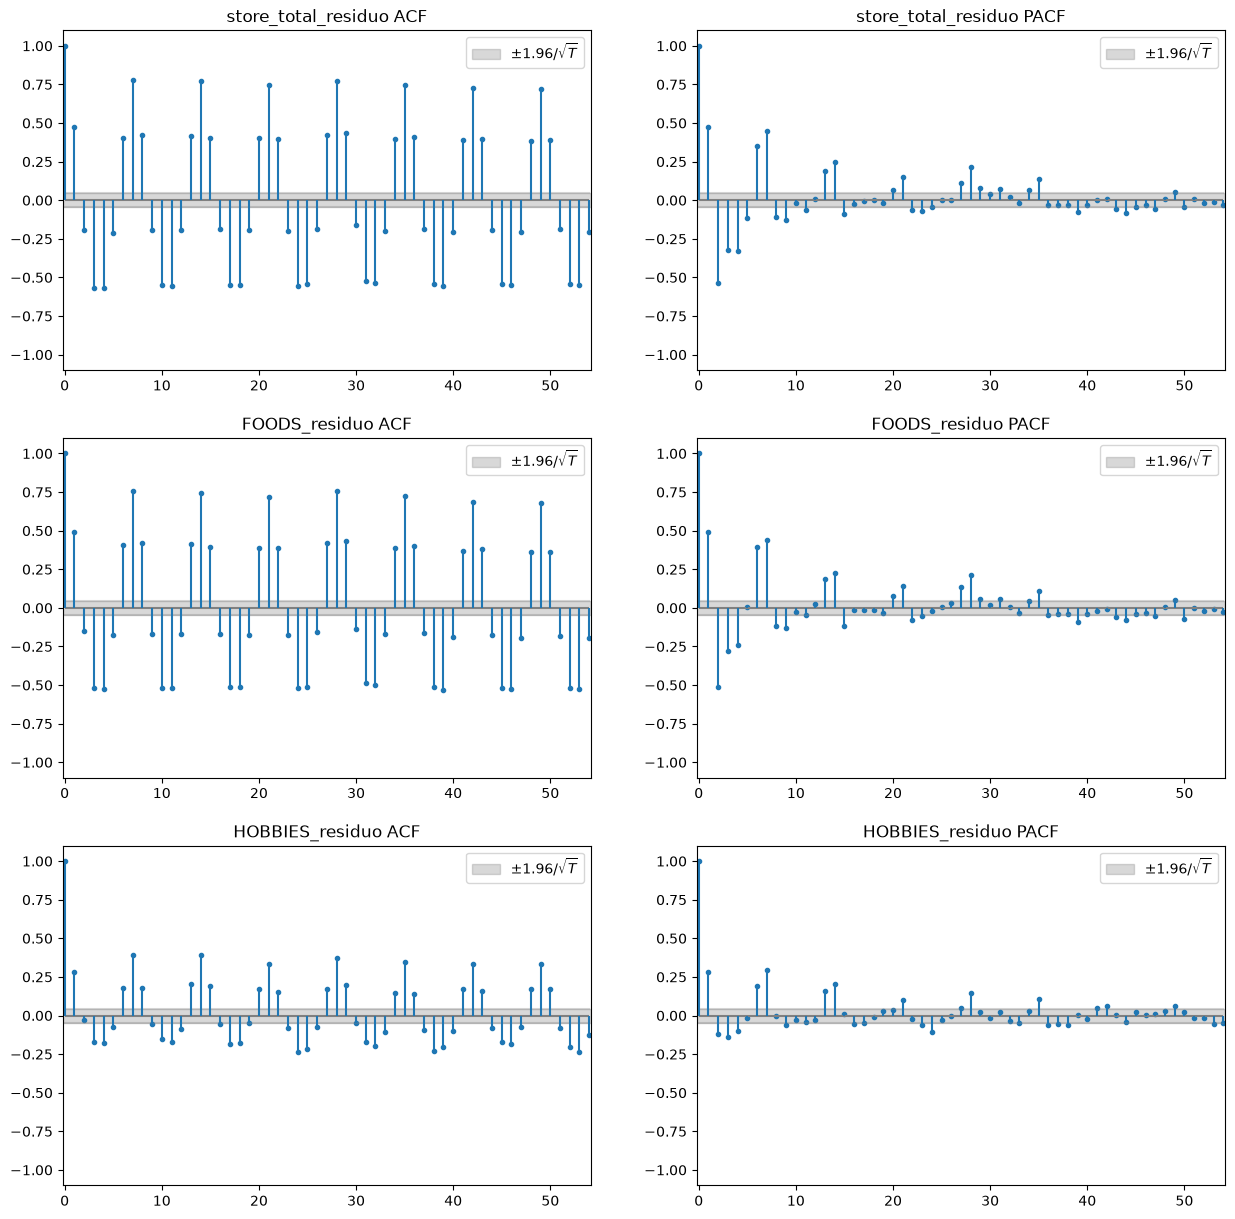

In [123]:
max_lag = 54
lags, acfs_store_total_residuo, pacfs_store_total_residuo = compute_serie_autocorrel(df=df_train, serie="store_total_residuo", max_lag=max_lag)
lags, acfs_FOODS_residuo, pacfs_FOODS_residuo = compute_serie_autocorrel(df=df_train, serie="FOODS_residuo", max_lag=max_lag)
lags, acfs_HOBBIES_residuo, pacfs_HOBBIES_residuo = compute_serie_autocorrel(df=df_train, serie="HOBBIES_residuo", max_lag=max_lag)
banda_pacf = banda_acf = np.full_like(acfs_store_total_residuo, 1.96 / np.sqrt(len(df_train)))

fig, axes = plt.subplots(len(series), 2, figsize=(15, 5*len(series)))
axes = np.ravel(axes)
plot_acf_pacf(lags, acfs_store_total_residuo, banda_acf, pacfs_store_total_residuo, banda_pacf, axes=axes[:2], serie_name="store_total_residuo")
plot_acf_pacf(lags, acfs_FOODS_residuo, banda_acf, pacfs_FOODS_residuo, banda_pacf, axes=axes[2:4], serie_name="FOODS_residuo")
plot_acf_pacf(lags, acfs_HOBBIES_residuo, banda_acf, pacfs_HOBBIES_residuo, banda_pacf, axes=axes[4:], serie_name="HOBBIES_residuo")